In [1]:
# Environment check (torch/numpy/pandas/sklearn ship with Colab by default)
import torch
print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Torch: 2.14.1+cu130
CUDA available: True
Using device: cuda


In [2]:
import os

CSV_PATH = "Xiatang.csv"

if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        print("Please select Xiatang.csv to upload...")
        uploaded = files.upload()
        CSV_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(
            f"{CSV_PATH} not found and google.colab not available. "
            "Set CSV_PATH to the correct location (e.g. a Google-Drive-mounted path)."
        )

print("Using file:", CSV_PATH)


Please select Xiatang.csv to upload...


Saving Xiatang.csv to Xiatang.csv
Using file: Xiatang.csv


In [3]:
MODEL_CONFIG = {
    # Task
    "task_name": "long_term_forecast",
    # Data
    "features": "M",
    "target": "DO",
    "seq_len": 24,
    "label_len": 12,
    "pred_len": 6,
    "enc_in": 9,
    "c_out": 1,
    # Architecture
    "d_model": 256,       # recommended for this dataset size (paper default: 512)
    "d_ff": 1024,          # recommended for this dataset size (paper default: 2048)
    "e_layers": 2,
    "dropout": 0.05,
    "activation": "gelu",
    # TimeMixer
    "down_sampling_layers": 2,
    "down_sampling_window": 2,
    "down_sampling_method": "avg",
    "channel_independence": False,
    # Decomposition
    "decomp_method": "moving_avg",
    "moving_avg": 25,
    # Embedding
    "embed": "timeF",
    "freq": "h",
    # Training
    "batch_size": 32,
    "learning_rate": 0.001,
    "train_epochs": 100,
    "patience": 10,
    # Misc
    "use_norm": True,
    "loss": "MSE",
}

INPUT_FEATURES = ["TEMP", "pH", "EC", "EUR", "COMMn", "NH3-N", "TP", "TN", "DO"]  # DO placed LAST (target)
TARGET = "DO"

assert len(INPUT_FEATURES) == MODEL_CONFIG["enc_in"]
assert INPUT_FEATURES[-1] == TARGET, "Target must be the LAST column for the model's de-norm step to work"

MODEL_CONFIG


{'task_name': 'long_term_forecast',
 'features': 'M',
 'target': 'DO',
 'seq_len': 24,
 'label_len': 12,
 'pred_len': 6,
 'enc_in': 9,
 'c_out': 1,
 'd_model': 256,
 'd_ff': 1024,
 'e_layers': 2,
 'dropout': 0.05,
 'activation': 'gelu',
 'down_sampling_layers': 2,
 'down_sampling_window': 2,
 'down_sampling_method': 'avg',
 'channel_independence': False,
 'decomp_method': 'moving_avg',
 'moving_avg': 25,
 'embed': 'timeF',
 'freq': 'h',
 'batch_size': 32,
 'learning_rate': 0.001,
 'train_epochs': 100,
 'patience': 10,
 'use_norm': True,
 'loss': 'MSE'}

In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv(CSV_PATH)
df.columns = [c.strip() for c in df.columns]
df["time"] = pd.to_datetime(df["time"])
df = df.sort_values("time").drop_duplicates(subset="time").set_index("time")

# Regular 4-hour grid from the first to the last timestamp (same setup as the other models)
grid = pd.date_range(df.index.min(), df.index.max(), freq="4h")
df = df[INPUT_FEATURES].reindex(grid)
df.index.name = "time"

# Fill gaps of up to 12 consecutive slots (2 days) by linear interpolation,
# then forward/backward fill any remaining gaps
df = df.interpolate(method="linear", limit=12, limit_direction="both")
df = df.ffill().bfill()
assert df.isna().sum().sum() == 0, "NaNs remain after gap filling"

df = df.reset_index()  # 'time' back as a column for build_time_features

print(f"Grid slots: {len(df)}")
print(f"Date range: {df['time'].min()} -> {df['time'].max()}")
df.head()


Grid slots: 10884
Date range: 2020-12-17 20:00:00 -> 2025-12-05 16:00:00


,time,TEMP,pH,EC,EUR,COMMn,NH3-N,TP,TN,DO
0,2020-12-17 20:00:00,1.600000,7.890000,385.25,23.250000,1.950000,0.03,0.0,1.280000,13.000000
1,2020-12-18 00:00:00,1.616667,7.888333,384.93,26.541667,2.001667,0.03,0.0,1.283333,13.001667
2,2020-12-18 04:00:00,1.633333,7.886667,384.61,29.833333,2.053333,0.03,0.0,1.286667,13.003333
3,2020-12-18 08:00:00,1.650000,7.885000,384.29,33.125000,2.105000,0.03,0.0,1.290000,13.005000
4,2020-12-18 12:00:00,1.666667,7.883333,383.97,36.416667,2.156667,0.03,0.0,1.293333,13.006667


In [5]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end]
val_df = df.iloc[train_end:val_end]
test_df = df.iloc[val_end:]

print(f"Train: {len(train_df)} rows | Val: {len(val_df)} rows | Test: {len(test_df)} rows")
# Expected (matches the report): 7618 | 1633 | 1633


Train: 7618 rows | Val: 1633 rows | Test: 1633 rows


In [6]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset


# ---------------------------------------------------------
# Time feature engineering (mirrors the standard "timeF" embedding
# used in Time-Series-Library: normalized calendar features)
# ---------------------------------------------------------
def build_time_features(dates: pd.Series, freq: str = "h") -> np.ndarray:
    dates = pd.to_datetime(dates)
    if freq.lower() == "h":
        feats = np.stack([
            dates.dt.hour / 23.0 - 0.5,
            dates.dt.dayofweek / 6.0 - 0.5,
            (dates.dt.day - 1) / 30.0 - 0.5,
            (dates.dt.dayofyear - 1) / 365.0 - 0.5,
        ], axis=1)
    elif freq.lower() == "d":
        feats = np.stack([
            dates.dt.dayofweek / 6.0 - 0.5,
            (dates.dt.day - 1) / 30.0 - 0.5,
            (dates.dt.dayofyear - 1) / 365.0 - 0.5,
        ], axis=1)
    else:
        feats = np.stack([
            dates.dt.hour / 23.0 - 0.5,
            dates.dt.dayofweek / 6.0 - 0.5,
            (dates.dt.day - 1) / 30.0 - 0.5,
            (dates.dt.dayofyear - 1) / 365.0 - 0.5,
        ], axis=1)
    return feats.astype(np.float32)


# ---------------------------------------------------------
# Windowed Dataset for long-term forecasting
# ---------------------------------------------------------
class ForecastDataset(Dataset):
    """
    Produces:
      seq_x      : (seq_len, enc_in)          -- encoder input, all features
      seq_y      : (label_len + pred_len, c_out) -- decoder input/target, target col only
      seq_x_mark : (seq_len, n_time_feats)
      seq_y_mark : (label_len + pred_len, n_time_feats)
    """
    def __init__(self, data, data_stamp, target_idx, seq_len, label_len, pred_len):
        self.data = data                 # (N, enc_in) scaled features, target placed LAST column
        self.data_stamp = data_stamp     # (N, n_time_feats)
        self.target_idx = target_idx     # index of target column within `data`
        self.seq_len = seq_len
        self.label_len = label_len
        self.pred_len = pred_len

    def __len__(self):
        return len(self.data) - self.seq_len - self.pred_len + 1

    def __getitem__(self, index):
        s_begin = index
        s_end = s_begin + self.seq_len
        r_begin = s_end - self.label_len
        r_end = s_end + self.pred_len

        seq_x = self.data[s_begin:s_end]                          # (seq_len, enc_in)
        seq_y = self.data[r_begin:r_end, self.target_idx:self.target_idx + 1]  # (label_len+pred_len, 1)
        seq_x_mark = self.data_stamp[s_begin:s_end]
        seq_y_mark = self.data_stamp[r_begin:r_end]

        return (
            torch.tensor(seq_x, dtype=torch.float32),
            torch.tensor(seq_y, dtype=torch.float32),
            torch.tensor(seq_x_mark, dtype=torch.float32),
            torch.tensor(seq_y_mark, dtype=torch.float32),
        )


In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(train_df[INPUT_FEATURES].values)

train_scaled = scaler.transform(train_df[INPUT_FEATURES].values)
val_scaled = scaler.transform(val_df[INPUT_FEATURES].values)
test_scaled = scaler.transform(test_df[INPUT_FEATURES].values)

target_idx = INPUT_FEATURES.index(TARGET)  # should be len(INPUT_FEATURES)-1

train_stamp = build_time_features(train_df["time"], freq=MODEL_CONFIG["freq"])
val_stamp = build_time_features(val_df["time"], freq=MODEL_CONFIG["freq"])
test_stamp = build_time_features(test_df["time"], freq=MODEL_CONFIG["freq"])

print("Scaled train shape:", train_scaled.shape, "| time-feature dim:", train_stamp.shape[1])


Scaled train shape: (7618, 9) | time-feature dim: 4


In [8]:
from torch.utils.data import DataLoader

seq_len = MODEL_CONFIG["seq_len"]
label_len = MODEL_CONFIG["label_len"]
pred_len = MODEL_CONFIG["pred_len"]
batch_size = MODEL_CONFIG["batch_size"]

train_dataset = ForecastDataset(train_scaled, train_stamp, target_idx, seq_len, label_len, pred_len)
val_dataset = ForecastDataset(val_scaled, val_stamp, target_idx, seq_len, label_len, pred_len)
test_dataset = ForecastDataset(test_scaled, test_stamp, target_idx, seq_len, label_len, pred_len)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, drop_last=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, drop_last=False)

print(f"Train windows: {len(train_dataset)} | Val windows: {len(val_dataset)} | Test windows: {len(test_dataset)}")

# sanity check on shapes: (batch, seq_len, enc_in) and (batch, pred_len)
sx, sy, sxm, sym = next(iter(train_loader))
print("seq_x:", sx.shape, "| seq_y:", sy.shape, "| seq_x_mark:", sxm.shape, "| seq_y_mark:", sym.shape)


Train windows: 7589 | Val windows: 1604 | Test windows: 1604
seq_x: torch.Size([32, 24, 9]) | seq_y: torch.Size([32, 18, 1]) | seq_x_mark: torch.Size([32, 24, 4]) | seq_y_mark: torch.Size([32, 18, 4])


In [9]:
# =========================================================
# TimeMixer -- from-scratch implementation
# Based on: "TimeMixer: Decomposable Multiscale Mixing for
# Time Series Forecasting" (ICLR 2024)
# =========================================================

import torch
import torch.nn as nn
import torch.nn.functional as F


# ---------------------------------------------------------
# 1. Series decomposition (moving-average trend/seasonal split)
# ---------------------------------------------------------
class MovingAvg(nn.Module):
    """Moving average block to extract the trend of a series using AvgPool1d."""
    def __init__(self, kernel_size, stride=1):
        super().__init__()
        self.kernel_size = kernel_size
        self.avg = nn.AvgPool1d(kernel_size=kernel_size, stride=stride, padding=0)

    def forward(self, x):
        # x: (B, T, C)
        front = x[:, 0:1, :].repeat(1, (self.kernel_size - 1) // 2, 1)
        end = x[:, -1:, :].repeat(1, (self.kernel_size - 1) // 2, 1)
        x = torch.cat([front, x, end], dim=1)
        x = self.avg(x.permute(0, 2, 1))
        x = x.permute(0, 2, 1)
        return x


class SeriesDecomp(nn.Module):
    """Decompose a series (B, T, C) into seasonal + trend components."""
    def __init__(self, kernel_size):
        super().__init__()
        self.moving_avg = MovingAvg(kernel_size, stride=1)

    def forward(self, x):
        trend = self.moving_avg(x)
        seasonal = x - trend
        return seasonal, trend


# ---------------------------------------------------------
# 2. Reversible Instance Normalization (RevIN) -- used when use_norm=True
# ---------------------------------------------------------
class RevIN(nn.Module):
    def __init__(self, num_features, eps=1e-5, affine=True):
        super().__init__()
        self.eps = eps
        self.affine = affine
        if affine:
            self.affine_weight = nn.Parameter(torch.ones(num_features))
            self.affine_bias = nn.Parameter(torch.zeros(num_features))

    def forward(self, x, mode):
        # x: (B, T, C)
        if mode == "norm":
            self.mean = x.mean(dim=1, keepdim=True).detach()
            self.stdev = torch.sqrt(x.var(dim=1, keepdim=True, unbiased=False) + self.eps).detach()
            x = (x - self.mean) / self.stdev
            if self.affine:
                x = x * self.affine_weight + self.affine_bias
            return x
        elif mode == "denorm":
            if self.affine:
                x = (x - self.affine_bias) / (self.affine_weight + self.eps)
            x = x * self.stdev + self.mean
            return x
        else:
            raise ValueError("mode must be 'norm' or 'denorm'")


# ---------------------------------------------------------
# 3. Data embedding: value projection + temporal (time-feature) embedding
# ---------------------------------------------------------
class TimeFeatureEmbedding(nn.Module):
    def __init__(self, d_model, freq="h"):
        super().__init__()
        freq_map = {"h": 4, "t": 5, "s": 6, "m": 1, "a": 1, "w": 2, "d": 3, "b": 3}
        d_inp = freq_map.get(freq, 4)
        self.embed = nn.Linear(d_inp, d_model, bias=False)

    def forward(self, x):
        return self.embed(x)


class DataEmbedding(nn.Module):
    """Projects (B, T, enc_in) -> (B, T, d_model) and adds a time-feature embedding."""
    def __init__(self, c_in, d_model, freq="h", dropout=0.05):
        super().__init__()
        self.value_embedding = nn.Linear(c_in, d_model)
        self.temporal_embedding = TimeFeatureEmbedding(d_model, freq)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, x_mark):
        if x_mark is None:
            out = self.value_embedding(x)
        else:
            out = self.value_embedding(x) + self.temporal_embedding(x_mark)
        return self.dropout(out)


# ---------------------------------------------------------
# 4. Multi-scale mixing components
# ---------------------------------------------------------
class MultiScaleSeasonalMixing(nn.Module):
    """Bottom-up mixing: fine (long, low index) -> coarse (short, high index) resolution."""
    def __init__(self, configs):
        super().__init__()
        self.down_sampling_layers = nn.ModuleList([
            nn.Sequential(
                nn.Linear(
                    configs["seq_len"] // (configs["down_sampling_window"] ** i),
                    configs["seq_len"] // (configs["down_sampling_window"] ** (i + 1)),
                ),
                nn.GELU(),
                nn.Linear(
                    configs["seq_len"] // (configs["down_sampling_window"] ** (i + 1)),
                    configs["seq_len"] // (configs["down_sampling_window"] ** (i + 1)),
                ),
            )
            for i in range(configs["down_sampling_layers"])
        ])

    def forward(self, season_list):
        # season_list: list of (B, C, T_i) tensors, T_i decreasing (fine -> coarse)
        out_high = season_list[0]
        out_low = season_list[1]
        out_season_list = [out_high.permute(0, 2, 1)]

        for i in range(len(season_list) - 1):
            out_low_res = self.down_sampling_layers[i](out_high)
            out_low = out_low + out_low_res
            out_high = out_low
            if i + 2 <= len(season_list) - 1:
                out_low = season_list[i + 2]
            out_season_list.append(out_high.permute(0, 2, 1))
        return out_season_list


class MultiScaleTrendMixing(nn.Module):
    """Top-down mixing: coarse (short, high index) -> fine (long, low index) resolution."""
    def __init__(self, configs):
        super().__init__()
        self.up_sampling_layers = nn.ModuleList([
            nn.Sequential(
                nn.Linear(
                    configs["seq_len"] // (configs["down_sampling_window"] ** (i + 1)),
                    configs["seq_len"] // (configs["down_sampling_window"] ** i),
                ),
                nn.GELU(),
                nn.Linear(
                    configs["seq_len"] // (configs["down_sampling_window"] ** i),
                    configs["seq_len"] // (configs["down_sampling_window"] ** i),
                ),
            )
            for i in reversed(range(configs["down_sampling_layers"]))
        ])

    def forward(self, trend_list):
        trend_list_reverse = trend_list.copy()
        trend_list_reverse.reverse()  # now coarse -> fine
        out_low = trend_list_reverse[0]
        out_high = trend_list_reverse[1]
        out_trend_list = [out_low.permute(0, 2, 1)]

        for i in range(len(trend_list_reverse) - 1):
            out_high_res = self.up_sampling_layers[i](out_low)
            out_high = out_high + out_high_res
            out_low = out_high
            if i + 2 <= len(trend_list_reverse) - 1:
                out_high = trend_list_reverse[i + 2]
            out_trend_list.append(out_low.permute(0, 2, 1))

        out_trend_list.reverse()
        return out_trend_list


class PastDecomposableMixing(nn.Module):
    """One PDM block: decompose each scale, mix seasonal bottom-up and trend
    top-down across scales, then recombine."""
    def __init__(self, configs):
        super().__init__()
        self.decomp = SeriesDecomp(configs["moving_avg"])
        self.d_model = configs["d_model"]

        self.cross_layer = nn.Sequential(
            nn.Linear(configs["d_model"], configs["d_ff"]),
            nn.GELU(),
            nn.Linear(configs["d_ff"], configs["d_model"]),
        )

        self.mixing_multi_scale_season = MultiScaleSeasonalMixing(configs)
        self.mixing_multi_scale_trend = MultiScaleTrendMixing(configs)

        self.out_cross_layer = nn.Sequential(
            nn.Linear(configs["d_model"], configs["d_ff"]),
            nn.GELU(),
            nn.Linear(configs["d_ff"], configs["d_model"]),
        )

    def forward(self, x_list):
        # x_list: list of (B, T_i, d_model), fine -> coarse
        length_list = [x.size(1) for x in x_list]

        season_list, trend_list = [], []
        for x in x_list:
            season, trend = self.decomp(x)
            season = self.cross_layer(season)
            trend = self.cross_layer(trend)
            season_list.append(season.permute(0, 2, 1))  # (B, d_model, T_i)
            trend_list.append(trend.permute(0, 2, 1))

        out_season_list = self.mixing_multi_scale_season(season_list)
        out_trend_list = self.mixing_multi_scale_trend(trend_list)

        out_list = []
        for orig, season, trend, length in zip(x_list, out_season_list, out_trend_list, length_list):
            out = season + trend
            out = self.out_cross_layer(out)
            out_list.append(orig + out[:, :length, :])
        return out_list


# ---------------------------------------------------------
# 5. Full TimeMixer model
# ---------------------------------------------------------
class TimeMixer(nn.Module):
    def __init__(self, configs):
        super().__init__()
        self.configs = configs
        self.seq_len = configs["seq_len"]
        self.pred_len = configs["pred_len"]
        self.down_sampling_layers = configs["down_sampling_layers"]
        self.down_sampling_window = configs["down_sampling_window"]
        self.channel_independence = configs["channel_independence"]
        self.use_norm = configs["use_norm"]
        self.enc_in = configs["enc_in"]
        self.c_out = configs["c_out"]

        self.pdm_blocks = nn.ModuleList(
            [PastDecomposableMixing(configs) for _ in range(configs["e_layers"])]
        )

        in_dim = 1 if self.channel_independence else self.enc_in
        self.enc_embedding = DataEmbedding(
            in_dim, configs["d_model"], configs["freq"], configs["dropout"]
        )

        self.normalize_layers = nn.ModuleList(
            [RevIN(self.enc_in) for _ in range(self.down_sampling_layers + 1)]
        )

        # per-scale predictor: project each scale's temporal dim -> pred_len
        self.predict_layers = nn.ModuleList([
            nn.Linear(
                configs["seq_len"] // (self.down_sampling_window ** i),
                configs["pred_len"],
            )
            for i in range(self.down_sampling_layers + 1)
        ])

        self.projection_layer = nn.Linear(configs["d_model"], self.c_out)

    # ---- multi-scale downsampling of the raw input ----
    def __multi_scale_process_inputs(self, x_enc, x_mark_enc):
        if self.configs["down_sampling_method"] == "avg":
            down_pool = nn.AvgPool1d(self.down_sampling_window)
        elif self.configs["down_sampling_method"] == "max":
            down_pool = nn.MaxPool1d(self.down_sampling_window)
        else:
            down_pool = nn.AvgPool1d(self.down_sampling_window)

        x_enc = x_enc.permute(0, 2, 1)  # (B, C, T)
        x_enc_ori = x_enc
        x_mark_ori = x_mark_enc

        x_enc_sampling_list = [x_enc.permute(0, 2, 1)]
        x_mark_sampling_list = [x_mark_enc] if x_mark_enc is not None else None

        for i in range(self.down_sampling_layers):
            x_enc_sampling = down_pool(x_enc_ori)
            x_enc_sampling_list.append(x_enc_sampling.permute(0, 2, 1))
            x_enc_ori = x_enc_sampling
            if x_mark_ori is not None:
                x_mark_sampling = x_mark_ori[:, ::self.down_sampling_window, :]
                x_mark_sampling_list.append(x_mark_sampling)
                x_mark_ori = x_mark_sampling

        return x_enc_sampling_list, x_mark_sampling_list

    def forecast(self, x_enc, x_mark_enc):
        # x_enc: (B, seq_len, enc_in) ; x_mark_enc: (B, seq_len, n_time_feats)
        x_list_raw, x_mark_list = self.__multi_scale_process_inputs(x_enc, x_mark_enc)

        # normalize each scale independently (RevIN, per-scale statistics)
        x_list = []
        for i, x in enumerate(x_list_raw):
            if self.use_norm:
                x = self.normalize_layers[i](x, "norm")
            x_list.append(x)

        # embed each scale -> (B, T_i, d_model)
        enc_list = []
        for i, x in enumerate(x_list):
            mark = x_mark_list[i] if x_mark_list is not None else None
            enc_list.append(self.enc_embedding(x, mark))

        # Past Decomposable Mixing blocks
        for pdm in self.pdm_blocks:
            enc_list = pdm(enc_list)

        # per-scale prediction, then sum across scales
        dec_out_list = []
        for i, enc in enumerate(enc_list):
            # enc: (B, T_i, d_model) -> (B, d_model, T_i) -> Linear -> (B, d_model, pred_len)
            dec = self.predict_layers[i](enc.permute(0, 2, 1)).permute(0, 2, 1)
            dec = self.projection_layer(dec)  # (B, pred_len, c_out)
            dec_out_list.append(dec)

        dec_out = torch.stack(dec_out_list, dim=-1).sum(-1)  # sum contributions of all scales

        if self.use_norm:
            # de-normalize using scale-0 (original resolution) statistics, restricted to target col(s)
            mean = self.normalize_layers[0].mean[:, :, -self.c_out:]
            stdev = self.normalize_layers[0].stdev[:, :, -self.c_out:]
            dec_out = dec_out * stdev + mean

        return dec_out

    def forward(self, x_enc, x_mark_enc, x_dec=None, x_mark_dec=None):
        return self.forecast(x_enc, x_mark_enc)


In [10]:
model = TimeMixer(MODEL_CONFIG).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}")

# forward-pass shape check
with torch.no_grad():
    out = model(sx.to(device), sxm.to(device))
    print("Model output shape:", out.shape, " (expected: (batch, pred_len, c_out))")


Trainable parameters: 2,109,893
Model output shape: torch.Size([32, 6, 1])  (expected: (batch, pred_len, c_out))


In [11]:
import numpy as np
import torch


class EarlyStopping:
    def __init__(self, patience=10, verbose=True, delta=0.0, path="checkpoint.pt"):
        self.patience = patience
        self.verbose = verbose
        self.delta = delta
        self.path = path
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = np.inf

    def __call__(self, val_loss, model):
        score = -val_loss
        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.verbose:
                print(f"  EarlyStopping counter: {self.counter}/{self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        if self.verbose:
            print(f"  Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}). Saving model...")
        torch.save(model.state_dict(), self.path)
        self.val_loss_min = val_loss


def compute_metrics(preds, trues):
    """preds, trues: numpy arrays, same shape (N, pred_len) or (N, pred_len, 1)."""
    preds = preds.reshape(-1)
    trues = trues.reshape(-1)

    mae = np.mean(np.abs(preds - trues))
    rmse = np.sqrt(np.mean((preds - trues) ** 2))
    # avoid div-by-zero in MAPE
    eps = 1e-6
    mape = np.mean(np.abs((preds - trues) / (np.abs(trues) + eps))) * 100
    ss_res = np.sum((trues - preds) ** 2)
    ss_tot = np.sum((trues - np.mean(trues)) ** 2)
    r2 = 1 - ss_res / (ss_tot + eps)

    return {"RMSE": rmse, "MAE": mae, "MAPE": mape, "R2": r2}


def run_epoch(model, loader, criterion, device, optimizer=None):
    """If optimizer is given -> training mode, else -> eval mode (no grad)."""
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    n_batches = 0

    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for seq_x, seq_y, seq_x_mark, seq_y_mark in loader:
            seq_x = seq_x.to(device)
            seq_y = seq_y.to(device)
            seq_x_mark = seq_x_mark.to(device)
            seq_y_mark = seq_y_mark.to(device)

            if is_train:
                optimizer.zero_grad()

            outputs = model(seq_x, seq_x_mark)          # (B, pred_len, c_out)
            target = seq_y[:, -outputs.shape[1]:, :]     # last pred_len steps

            loss = criterion(outputs, target)

            if is_train:
                loss.backward()
                optimizer.step()

            total_loss += loss.item()
            n_batches += 1

    return total_loss / max(n_batches, 1)


def predict(model, loader, device):
    model.eval()
    all_preds, all_trues = [], []
    with torch.no_grad():
        for seq_x, seq_y, seq_x_mark, seq_y_mark in loader:
            seq_x = seq_x.to(device)
            seq_x_mark = seq_x_mark.to(device)
            outputs = model(seq_x, seq_x_mark)           # (B, pred_len, c_out)
            target = seq_y[:, -outputs.shape[1]:, :]

            all_preds.append(outputs.cpu().numpy())
            all_trues.append(target.numpy())

    preds = np.concatenate(all_preds, axis=0)
    trues = np.concatenate(all_trues, axis=0)
    return preds, trues


In [12]:
import torch.nn as nn
import torch.optim as optim
import time

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=MODEL_CONFIG["learning_rate"])
early_stopping = EarlyStopping(patience=MODEL_CONFIG["patience"], verbose=True, path="timemixer_best.pt")

train_losses, val_losses = [], []

for epoch in range(1, MODEL_CONFIG["train_epochs"] + 1):
    t0 = time.time()
    train_loss = run_epoch(model, train_loader, criterion, device, optimizer=optimizer)
    val_loss = run_epoch(model, val_loader, criterion, device, optimizer=None)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"Epoch {epoch:3d}/{MODEL_CONFIG['train_epochs']} | "
          f"train_loss={train_loss:.6f} | val_loss={val_loss:.6f} | "
          f"time={time.time()-t0:.1f}s")

    early_stopping(val_loss, model)
    if early_stopping.early_stop:
        print(f"Early stopping triggered at epoch {epoch}.")
        break

# restore best checkpoint
model.load_state_dict(torch.load("timemixer_best.pt"))
print("Loaded best model (lowest val loss).")


Epoch   1/100 | train_loss=0.077557 | val_loss=0.027322 | time=6.9s
  Validation loss decreased (inf --> 0.027322). Saving model...
Epoch   2/100 | train_loss=0.060561 | val_loss=0.021666 | time=7.5s
  Validation loss decreased (0.027322 --> 0.021666). Saving model...
Epoch   3/100 | train_loss=0.049946 | val_loss=0.021574 | time=8.2s
  Validation loss decreased (0.021666 --> 0.021574). Saving model...
Epoch   4/100 | train_loss=0.052361 | val_loss=0.020646 | time=6.7s
  Validation loss decreased (0.021574 --> 0.020646). Saving model...
Epoch   5/100 | train_loss=0.050751 | val_loss=0.022267 | time=7.2s
  EarlyStopping counter: 1/10
Epoch   6/100 | train_loss=0.047374 | val_loss=0.021680 | time=6.5s
  EarlyStopping counter: 2/10
Epoch   7/100 | train_loss=0.045676 | val_loss=0.022461 | time=7.3s
  EarlyStopping counter: 3/10
Epoch   8/100 | train_loss=0.043678 | val_loss=0.020956 | time=6.6s
  EarlyStopping counter: 4/10
Epoch   9/100 | train_loss=0.045878 | val_loss=0.034222 | time=7.

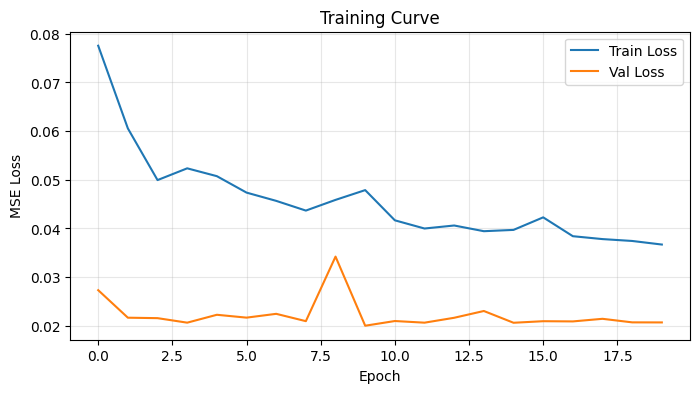

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [15]:
preds, trues = predict(model, test_loader, device)   # both: (N, pred_len, 1), standardized scale
print("Raw preds shape:", preds.shape)

# inverse-transform back to original DO units
target_mean = scaler.mean_[target_idx]
target_std = scaler.scale_[target_idx]

preds_inv = preds * target_std + target_mean
trues_inv = trues * target_std + target_mean

metrics = compute_metrics(preds_inv, trues_inv)
print("Test set metrics (original DO units):")
for k, v in metrics.items():
    print(f"  {k:6s}: {v:.4f}")


Raw preds shape: (1604, 6, 1)
Test set metrics (original DO units):
  RMSE  : 0.4193
  MAE   : 0.2623
  MAPE  : 3.4488
  R2    : 0.9045


In [16]:
# Metrics broken down by forecast horizon step (1..pred_len)
print(f"{'Step':>5} {'RMSE':>8} {'MAE':>8} {'MAPE':>8} {'R2':>8}")
for step in range(pred_len):
    m = compute_metrics(preds_inv[:, step, :], trues_inv[:, step, :])
    print(f"{step+1:>5} {m['RMSE']:>8.4f} {m['MAE']:>8.4f} {m['MAPE']:>8.2f} {m['R2']:>8.4f}")


 Step     RMSE      MAE     MAPE       R2
    1   0.3140   0.1921     2.52   0.9468
    2   0.3849   0.2403     3.17   0.9198
    3   0.4222   0.2663     3.51   0.9033
    4   0.4383   0.2777     3.65   0.8955
    5   0.4548   0.2888     3.80   0.8873
    6   0.4806   0.3083     4.05   0.8738


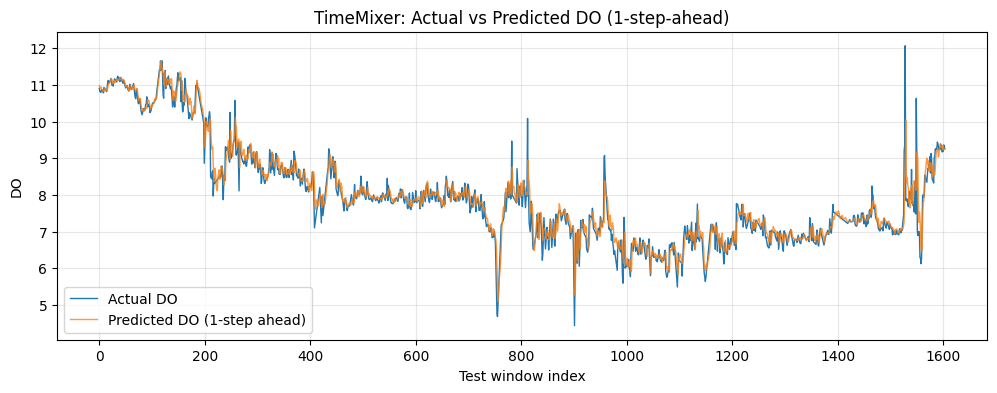

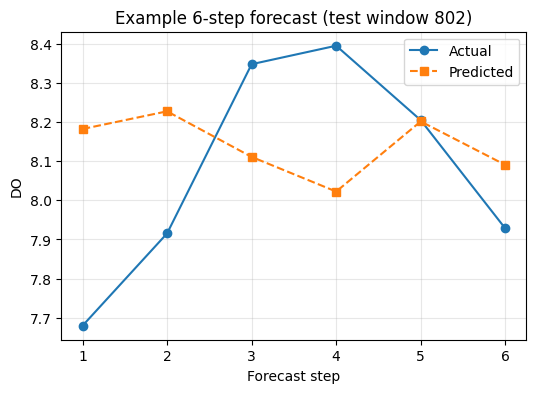

In [17]:
# Plot: predicted vs actual DO over the test set (using the 1-step-ahead prediction of each window)
plt.figure(figsize=(12, 4))
plt.plot(trues_inv[:, 0, 0], label="Actual DO", linewidth=1)
plt.plot(preds_inv[:, 0, 0], label="Predicted DO (1-step ahead)", linewidth=1, alpha=0.8)
plt.xlabel("Test window index")
plt.ylabel("DO")
plt.title("TimeMixer: Actual vs Predicted DO (1-step-ahead)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot a single example forecast window (full pred_len horizon)
idx = len(preds_inv) // 2
plt.figure(figsize=(6, 4))
plt.plot(range(1, pred_len + 1), trues_inv[idx, :, 0], "o-", label="Actual")
plt.plot(range(1, pred_len + 1), preds_inv[idx, :, 0], "s--", label="Predicted")
plt.xlabel("Forecast step")
plt.ylabel("DO")
plt.title(f"Example {pred_len}-step forecast (test window {idx})")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
